# Bayesian Reasoning

This notebook demonstrates Bayesian reasoning using examples from
David Barber's book "Bayesian Reasoning and Machine Learning".
We cover the concepts of prior, likelihood, posterior, and
provide a detailed example of a pendulum with noisy measurements.

In [2]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

## Prior, Likelihood, and Posterior

In Bayesian reasoning, we are often interested in inferring the
probability of a hypothesis $\theta$ given some observed data
$\mathcal{D}$. This is achieved using Bayes' theorem, which
relates the **prior**, **likelihood**, and **posterior** probabilities.

### Bayes' Theorem

Bayes' theorem is stated as:

$$
p(\theta \mid \mathcal{D}) = \frac{p(\mathcal{D} \mid \theta) \, p(\theta)}{p(\mathcal{D})},
$$

where:
- $p(\theta \mid \mathcal{D})$ is the **posterior probability**
  of the hypothesis $\theta$ given the data $\mathcal{D}$.
- $p(\mathcal{D} \mid \theta)$ is the **likelihood** of the
  data $\mathcal{D}$ under the hypothesis $\theta$.
- $p(\theta)$ is the **prior probability** of the hypothesis
  $\theta$, representing our beliefs about $\theta$ before
  observing the data.
- $p(\mathcal{D})$ is the **marginal likelihood** (or evidence),
  which acts as a normalizing constant to ensure the posterior
  probability sums to 1.

### Prior Probability

The prior probability $p(\theta)$ encodes our initial beliefs
about the hypothesis $\theta$ before observing any data. For
example, if $\theta$ represents the probability of a coin
landing heads, a reasonable prior might be a uniform distribution,
reflecting no initial bias toward heads or tails.

In this example, we use a **non-uniform prior** (a Gaussian distribution)
to reflect specific beliefs about $\theta$.

### Likelihood

The likelihood $p(\mathcal{D} \mid \theta)$ quantifies how well
the hypothesis $\theta$ explains the observed data $\mathcal{D}$.
For example, if $\theta$ is the probability of a coin landing
heads, and we observe 7 heads in 10 flips, the likelihood measures
how probable this outcome is under the hypothesis $\theta$.

### Posterior Probability

The posterior probability $p(\theta \mid \mathcal{D})$ represents
our updated beliefs about the hypothesis $\theta$ after observing
the data $\mathcal{D}$. It combines the prior probability and the
likelihood using Bayes' theorem. The posterior is proportional to the
product of the prior and the likelihood:

$$
p(\theta \mid \mathcal{D}) \propto p(\mathcal{D} \mid \theta) \, p(\theta).
$$

### Marginal Likelihood

The marginal likelihood $p(\mathcal{D})$ is computed by summing
(or integrating) over all possible hypotheses:

$$
p(\mathcal{D}) = \sum_{\theta} p(\mathcal{D} \mid \theta) \, p(\theta).
$$

This ensures that the posterior probability is properly normalized.

### Generative Model and Posterior Inference

Bayesian reasoning allows us to infer the posterior distribution
$p(\theta \mid \mathcal{D})$ of a variable $\theta$ given
observed data $\mathcal{D}$. This is achieved by combining a
**forward** or **generative model** $p(\mathcal{D} \mid \theta)$
with a **prior belief** $p(\theta)$ about the variable. The
generative model describes how the data $\mathcal{D}$ is generated
from the variable $\theta$, while the prior encodes our initial
beliefs about plausible values of $\theta$.

### Maximum a Posteriori (MAP) Estimation

The **most probable a posteriori (MAP)** setting is the value of
$\theta$ that maximizes the posterior distribution:

$$
\theta^* = \underset{\theta}{\operatorname{argmax}} \, p(\theta \mid \mathcal{D}).
$$

This represents the most plausible value of $\theta$ given the
observed data $\mathcal{D}$ and the prior $p(\theta)$.

### Connection to Maximum Likelihood (ML)

When the prior $p(\theta)$ is **flat** (i.e., a constant that
does not depend on $\theta$), the posterior distribution is
proportional to the likelihood:

$$
p(\theta \mid \mathcal{D}) \propto p(\mathcal{D} \mid \theta).
$$

In this case, the MAP solution reduces to the **Maximum Likelihood
(ML)** estimate:

$$
\theta^* = \underset{\theta}{\operatorname{argmax}} \, p(\mathcal{D} \mid \theta).
$$

The ML estimate is the value of $\theta$ that maximizes the
likelihood of the observed data $\mathcal{D}$, ignoring any prior
information about $\theta$.

### Example: Pendulum (Inspired by Barber's Book "Bayesian Reasoning and Machine Learning")

Consider an idealised pendulum where $x_t$ is the angular displacement
of the pendulum at time $t$. Assuming that the measurements are
independent given the parameter $\theta$, the likelihood of a sequence
of observations $x_1, \dots, x_T$ is given by:

$$
p(x_1, \dots, x_T \mid \theta) = \prod_{t=1}^T p(x_t \mid \theta).
$$

If the model is perfect and the measurements are perfect, the physical
model is:

$$
x_t = \sin(\theta t),
$$

where $\theta$ represents the unknown physical constants of the
pendulum (e.g., $\theta = \sqrt{g/L}$, where $g$ is the
gravitational acceleration and $L$ is the length of the pendulum).

However, if the measurement instrument is poor, with a known variance
$\sigma^2$, the model becomes:

$$
x_t = \sin(\theta t) + \epsilon_t,
$$

where $\epsilon_t$ is zero-mean Gaussian noise with variance $\sigma^2$.

We can place a prior $p(\theta)$ over the possible values of $\theta$,
expressing our prior belief in the appropriateness of different values.

The posterior distribution is then given by:

$$
p(\theta \mid x_1, \dots, x_T) \propto p(\theta) \prod_{t=1}^T p(x_t \mid \theta).
$$


### Derivation of the Posterior

The posterior distribution is derived using **Bayes' theorem** and the assumption that the observations $ x_1, \dots, x_T $ are **conditionally independent** given $\theta$.

#### Bayes' Theorem

Bayes' theorem states that the posterior distribution is proportional to the product of the prior and the likelihood:

$$
p(\theta \mid x_1, \dots, x_T) = \frac{p(x_1, \dots, x_T \mid \theta) \, p(\theta)}{p(x_1, \dots, x_T)}.
$$

Since the marginal likelihood $ p(x_1, \dots, x_T) $ does not depend on $ \theta $, we can write:

$$
p(\theta \mid x_1, \dots, x_T) \propto p(x_1, \dots, x_T \mid \theta) \, p(\theta).
$$

#### Conditional Independence

The key assumption is that the observations $ x_1, \dots, x_T $ are conditionally independent given $ \theta $. This means:

$$
p(x_1, \dots, x_T \mid \theta) = \prod_{t=1}^T p(x_t \mid \theta).
$$

Substituting this into Bayes' theorem gives:

$$
p(\theta \mid x_1, \dots, x_T) \propto p(\theta) \prod_{t=1}^T p(x_t \mid \theta).
$$

#### Interpretation

- The **prior** $ p(\theta) $ encodes our initial beliefs about $ \theta $.
- The **likelihood** $ \prod_{t=1}^T p(x_t \mid \theta) $ measures how well $ \theta $ explains the observed data.
- The **posterior** combines the prior and likelihood to provide updated beliefs about $ \theta $.

In [16]:
# Parameters
theta_true = 0.09  # True value of theta
sigma = 0.1        # Standard deviation of measurement noise
T = 100            # Number of time steps
t = np.arange(1, T + 1)

# Simulate noisy measurements
np.random.seed(42)
x_t = np.sin(theta_true * t) + sigma * np.random.randn(T)

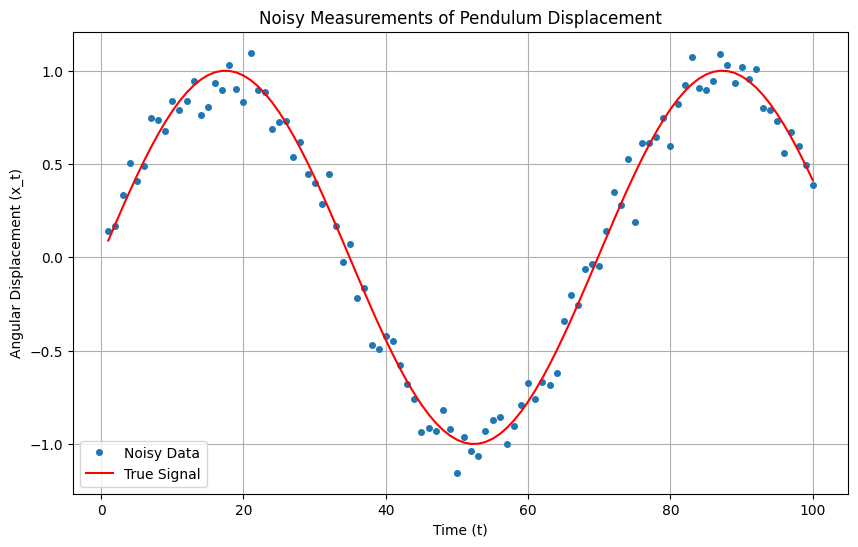

In [17]:
# Plot the noisy data
plt.figure(figsize=(10, 6))
plt.plot(t, x_t, "o", label="Noisy Data", markersize=4)
plt.plot(t, np.sin(theta_true * t), label="True Signal", color="red")
plt.xlabel("Time (t)")
plt.ylabel("Angular Displacement (x_t)")
plt.title("Noisy Measurements of Pendulum Displacement")
plt.legend()
plt.grid()
plt.show()

### Define Prior and Likelihood

We define a **non-uniform prior** (Gaussian) and a Gaussian likelihood.

In [19]:
# Define the prior (Gaussian)
mu_prior = 0.1          # Mean of the prior
sigma_prior = 0.05      # Standard deviation of the prior

def prior(theta):
    # Gaussian prior
    return norm.pdf(theta, loc=mu_prior, scale=sigma_prior)

# Define the likelihood (Gaussian)
def likelihood(theta, x_t, t):
    # Gaussian likelihood
    return np.prod(norm.pdf(x_t, loc=np.sin(theta * t), scale=sigma))

### Compute and Plot Prior, Likelihood, and Posterior

We compute the posterior distribution and plot the prior, likelihood, and posterior.

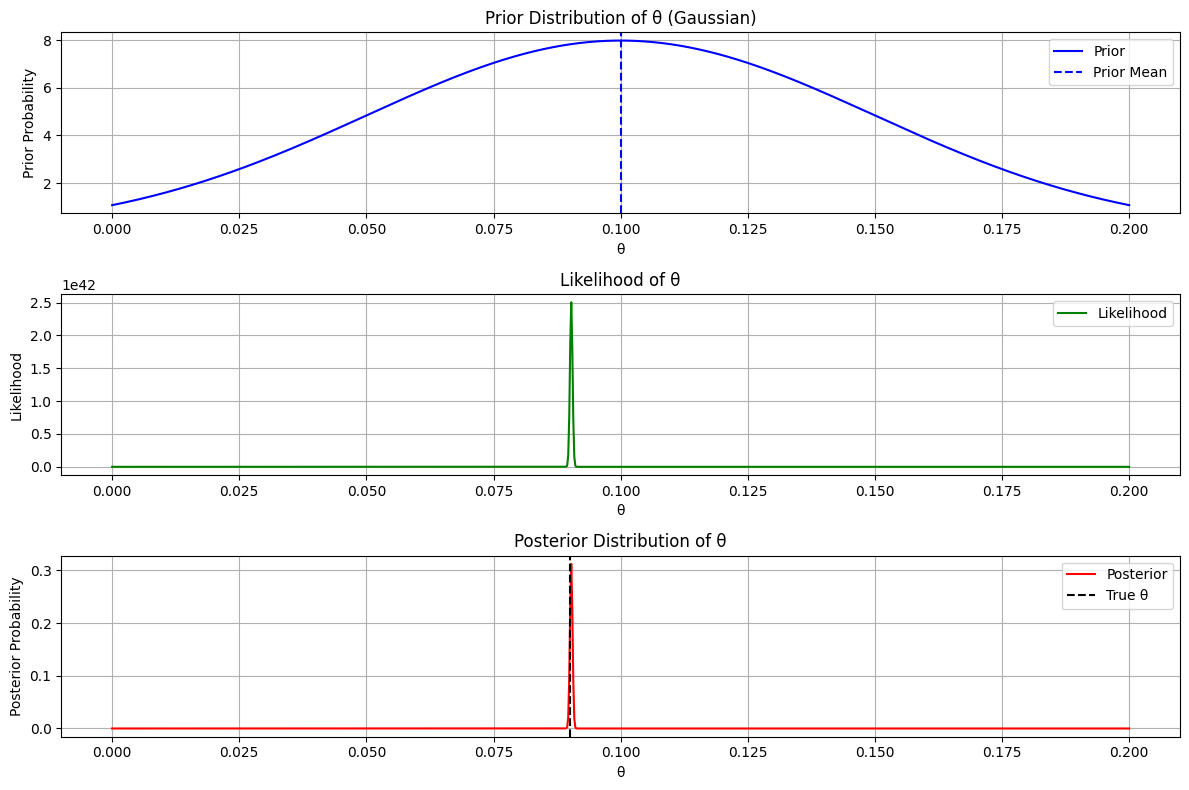

In [21]:
# Compute the posterior for a range of theta values
theta_values = np.linspace(0, 0.2, 1000)  # Range of theta values
posterior = np.array([prior(theta) * likelihood(theta, x_t, t) for theta in theta_values])
posterior /= np.sum(posterior)  # Normalize the posterior

# Plot the prior, likelihood, and posterior
plt.figure(figsize=(12, 8))

# Plot the prior
plt.subplot(3, 1, 1)
plt.plot(theta_values, prior(theta_values), label="Prior", color="blue")
plt.axvline(mu_prior, color="blue", linestyle="--", label="Prior Mean")
plt.xlabel("θ")
plt.ylabel("Prior Probability")
plt.title("Prior Distribution of θ (Gaussian)")
plt.legend()
plt.grid()

# Plot the likelihood
plt.subplot(3, 1, 2)
likelihood_values = np.array([likelihood(theta, x_t, t) for theta in theta_values])
plt.plot(theta_values, likelihood_values, label="Likelihood", color="green")
plt.xlabel("θ")
plt.ylabel("Likelihood")
plt.title("Likelihood of θ")
plt.legend()
plt.grid()

# Plot the posterior
plt.subplot(3, 1, 3)
plt.plot(theta_values, posterior, label="Posterior", color="red")
plt.axvline(theta_true, color="black", linestyle="--", label="True θ")
plt.xlabel("θ")
plt.ylabel("Posterior Probability")
plt.title("Posterior Distribution of θ")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

### Explanation of the Results

1. **Prior**:
   - The prior is a Gaussian distribution centered at $\theta = 0.1$ with a standard deviation of $0.05$.
   - This reflects our initial belief that $\theta$ is likely close to $0.1$ but with some uncertainty.

2. **Likelihood**:
   - The likelihood is computed based on the observed data and is peaked around the true value $\theta = 0.09$.

3. **Posterior**:
   - The posterior combines the prior and likelihood, providing updated beliefs about $\theta$.
   - The posterior is peaked closer to the true value $\theta = 0.09$, reflecting the influence of the data.

This example demonstrates how Bayesian inference updates our beliefs about a parameter using both prior knowledge and observed data.